In [ ]:
from google.colab import drive
drive.mount("/content/drive", force_remount=False)

from datetime import datetime, timezone
from pathlib import Path
import json
import os

UPSTREAM_COMMIT = "b76b93da8bd3096a99964a96ae29d46f197a0651"
PROJECT_ROOT = Path("/content/drive/MyDrive/CS2203_MuSc")
RUNS_ROOT = PROJECT_ROOT / "runs"
EXPORT_ROOT = PROJECT_ROOT / "exports"
SOURCE_E02_RUN_ID = "20261012_171400_E02_visa_all_clip_l14_336_baseline"
SOURCE_E02_ROOT = RUNS_ROOT / SOURCE_E02_RUN_ID
ACTIVE_Q_RUN_FILE = PROJECT_ROOT / "active-e02q-run.txt"

CATEGORIES = [
    "candle", "capsules", "cashew", "chewinggum", "fryum",
    "macaroni1", "macaroni2", "pcb1", "pcb2", "pcb3",
    "pcb4", "pipe_fryum",
]
QUAL_CATEGORIES = ["pcb2", "pcb3", "pcb4", "fryum"]

RUNS_ROOT.mkdir(parents=True, exist_ok=True)
EXPORT_ROOT.mkdir(parents=True, exist_ok=True)

if ACTIVE_Q_RUN_FILE.is_file():
    candidate_id = ACTIVE_Q_RUN_FILE.read_text(encoding="utf-8").strip()
    candidate_root = RUNS_ROOT / candidate_id
    if candidate_root.is_dir() and not (candidate_root / "E02Q_DONE.json").exists():
        RUN_ID = candidate_id
        print("Tiếp tục E02Q Run ID:", RUN_ID)
    else:
        ACTIVE_Q_RUN_FILE.unlink()
        RUN_ID = datetime.now().strftime("%Y%m%d_%H%M%S_E02Q_visa_qualitative")
        ACTIVE_Q_RUN_FILE.write_text(RUN_ID + "\n", encoding="utf-8")
        print("Tạo E02Q Run ID mới:", RUN_ID)
else:
    RUN_ID = datetime.now().strftime("%Y%m%d_%H%M%S_E02Q_visa_qualitative")
    ACTIVE_Q_RUN_FILE.write_text(RUN_ID + "\n", encoding="utf-8")
    print("Tạo E02Q Run ID mới:", RUN_ID)

RUN_ROOT = RUNS_ROOT / RUN_ID
CATEGORY_ROOT = RUN_ROOT / "categories"
SESSION_ID = datetime.now().strftime("%Y%m%d_%H%M%S")
SESSION_ROOT = RUN_ROOT / "sessions" / SESSION_ID

CATEGORY_ROOT.mkdir(parents=True, exist_ok=True)
SESSION_ROOT.mkdir(parents=True, exist_ok=False)

assert SOURCE_E02_ROOT.is_dir(), f"Không tìm thấy E02 nguồn: {SOURCE_E02_ROOT}"
assert (SOURCE_E02_ROOT / "E02_AGGREGATED.json").is_file()
assert (SOURCE_E02_ROOT / "visa_reproduced.csv").is_file()
assert (SOURCE_E02_ROOT / "dataset-source.txt").is_file()

(RUN_ROOT / "run-id.txt").write_text(RUN_ID + "\n", encoding="utf-8")
(RUN_ROOT / "source-e02-run-id.txt").write_text(
    SOURCE_E02_RUN_ID + "\n", encoding="utf-8"
)

print("E02Q run root:", RUN_ROOT)
print("E02 source root:", SOURCE_E02_ROOT)

Mounted at /content/drive
Tiếp tục E02Q Run ID: 20261014_050040_E02Q_visa_qualitative
E02Q run root: /content/drive/MyDrive/CS2203_MuSc/runs/20261014_050040_E02Q_visa_qualitative
E02 source root: /content/drive/MyDrive/CS2203_MuSc/runs/20261012_171400_E02_visa_all_clip_l14_336_baseline


In [ ]:
import platform
import subprocess
import sys

subprocess.run(
    [
        sys.executable,
        "-m",
        "pip",
        "install",
        "-q",
        "--upgrade",
        "huggingface_hub",
        "ftfy==6.1.3",
        "openpyxl==3.1.2",
        "timm==0.9.12",
    ],
    check=True,
)

import cv2
import ftfy
import openpyxl
import sklearn
import skimage
import timm
import torch
import torchvision

assert torch.cuda.is_available(), "GPU chưa được bật hoặc Colab chưa cấp GPU."

versions = {
    "python": sys.version,
    "platform": platform.platform(),
    "torch": torch.__version__,
    "torchvision": torchvision.__version__,
    "cuda_runtime": torch.version.cuda,
    "gpu": torch.cuda.get_device_name(0),
    "opencv": cv2.__version__,
    "ftfy": ftfy.__version__,
    "openpyxl": openpyxl.__version__,
    "scikit_learn": sklearn.__version__,
    "scikit_image": skimage.__version__,
    "timm": timm.__version__,
    "upstream_commit": UPSTREAM_COMMIT,
}

environment_text = "\n".join(f"{key}={value}" for key, value in versions.items())
(SESSION_ROOT / "environment.txt").write_text(environment_text + "\n", encoding="utf-8")
print(environment_text)
subprocess.run(["nvidia-smi"], check=True)

python=3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
platform=Linux-6.6.122+-x86_64-with-glibc2.39
torch=2.11.0+cu130
torchvision=0.26.0+cu130
cuda_runtime=13.0
gpu=Tesla T4
opencv=4.14.0
ftfy=6.1.2
openpyxl=3.1.2
scikit_learn=1.6.1
scikit_image=0.25.2
timm=0.9.12
upstream_commit=b76b93da8bd3096a99964a96ae29d46f197a0651


CompletedProcess(args=['nvidia-smi'], returncode=0)

In [ ]:
from datetime import datetime
import hashlib
import shutil
import subprocess

VISA_URL = "https://amazon-visual-anomaly.s3.us-west-2.amazonaws.com/VisA_20220922.tar"
DRIVE_DATASET_CACHE = PROJECT_ROOT / "cache" / "visa"
DRIVE_DATASET_CACHE.mkdir(parents=True, exist_ok=True)
DRIVE_ARCHIVE = DRIVE_DATASET_CACHE / "VisA_20220922.tar"
LOCAL_ARCHIVE = Path("/content/VisA_20220922.tar")
LOCAL_PARTIAL = Path("/content/VisA_20220922.tar.partial")

def valid_tar(path):
    candidate = Path(path)
    if not candidate.is_file() or candidate.stat().st_size < 1_000_000_000:
        return False, "File thiếu hoặc nhỏ bất thường."
    result = subprocess.run(
        ["tar", "-tf", str(candidate)],
        stdout=subprocess.DEVNULL,
        stderr=subprocess.PIPE,
        text=True,
    )
    return result.returncode == 0, result.stderr.strip()

if DRIVE_ARCHIVE.is_file():
    print("Đang sao chép VisA archive từ Drive xuống /content...")
    shutil.copy2(DRIVE_ARCHIVE, LOCAL_ARCHIVE)
    cached_valid, cached_message = valid_tar(LOCAL_ARCHIVE)
    print("Drive cache valid:", cached_valid)
    if not cached_valid:
        invalid_name = DRIVE_ARCHIVE.with_name(
            DRIVE_ARCHIVE.name + ".invalid-" + datetime.now().strftime("%Y%m%d_%H%M%S")
        )
        DRIVE_ARCHIVE.replace(invalid_name)
        LOCAL_ARCHIVE.unlink(missing_ok=True)
        print("Đã giữ cache lỗi tại:", invalid_name)
        print("Lý do:", cached_message)

if not LOCAL_ARCHIVE.is_file():
    LOCAL_PARTIAL.unlink(missing_ok=True)
    print("Đang tải VisA từ Amazon S3 chính thức...")
    subprocess.run(
        [
            "curl", "-L", "--fail", "--retry", "5",
            "--output", str(LOCAL_PARTIAL), VISA_URL,
        ],
        check=True,
    )
    downloaded_valid, downloaded_message = valid_tar(LOCAL_PARTIAL)
    print("Downloaded archive valid:", downloaded_valid)
    print("Archive check:", downloaded_message or "OK")
    assert downloaded_valid, "VisA archive tải xuống không hợp lệ."
    LOCAL_PARTIAL.replace(LOCAL_ARCHIVE)

local_valid, local_message = valid_tar(LOCAL_ARCHIVE)
assert local_valid, f"Local TAR không hợp lệ: {local_message}"

if not DRIVE_ARCHIVE.is_file() or DRIVE_ARCHIVE.stat().st_size != LOCAL_ARCHIVE.stat().st_size:
    print("Đang lưu archive hợp lệ vào Drive cache...")
    shutil.copy2(LOCAL_ARCHIVE, DRIVE_ARCHIVE)

sha256 = hashlib.sha256()
with LOCAL_ARCHIVE.open("rb") as stream:
    for chunk in iter(lambda: stream.read(8 * 1024 * 1024), b""):
        sha256.update(chunk)
archive_sha256 = sha256.hexdigest()

extract_root = Path("/content/visa-extract")
if extract_root.exists():
    shutil.rmtree(extract_root)
extract_root.mkdir(parents=True, exist_ok=False)

print("Đang giải nén VisA...")
subprocess.run(
    ["tar", "-xf", str(LOCAL_ARCHIVE), "-C", str(extract_root)],
    check=True,
)

split_files = list(extract_root.rglob("split_csv/1cls.csv"))
assert len(split_files) == 1, f"Không xác định được duy nhất VisA root: {split_files}"
DATA_ROOT = split_files[0].parent.parent

for category in CATEGORIES:
    required_paths = [
        DATA_ROOT / category / "Data" / "Images" / "Normal",
        DATA_ROOT / category / "Data" / "Images" / "Anomaly",
        DATA_ROOT / category / "Data" / "Masks" / "Anomaly",
        DATA_ROOT / category / "image_anno.csv",
    ]
    for required in required_paths:
        assert required.exists(), f"Thiếu dữ liệu: {required}"

DATA_SOURCE = VISA_URL
dataset_source_text = (
    f"source={DATA_SOURCE}\n"
    "archive=VisA_20220922.tar\n"
    f"sha256={archive_sha256}\n"
    f"resolved_root={DATA_ROOT}\n"
)
dataset_source_path = RUN_ROOT / "dataset-source.txt"
if dataset_source_path.exists():
    previous = dataset_source_path.read_text(encoding="utf-8").splitlines()
    assert previous[0] == f"source={DATA_SOURCE}", "Nguồn dataset thay đổi khi resume."
    assert previous[2] == f"sha256={archive_sha256}", "SHA-256 dataset thay đổi khi resume."
else:
    dataset_source_path.write_text(dataset_source_text, encoding="utf-8")

print("Archive SHA-256:", archive_sha256)
print("Dataset root:", DATA_ROOT)
print("Đã xác nhận đủ 12 category VisA.")

Đang sao chép VisA archive từ Drive xuống /content...
Drive cache valid: True
Đang giải nén VisA...
Archive SHA-256: 2eb8690c803ab37de0324772964100169ec8ba1fa3f7e94291c9ca673f40f362
Dataset root: /content/visa-extract
Đã xác nhận đủ 12 category VisA.


In [ ]:
import shutil
import subprocess

REPO_ROOT = Path("/content/MuSc")
if REPO_ROOT.exists():
    shutil.rmtree(REPO_ROOT)

subprocess.run(
    ["git", "clone", "https://github.com/xrli-U/MuSc.git", str(REPO_ROOT)],
    check=True,
)
subprocess.run(
    ["git", "checkout", "--detach", UPSTREAM_COMMIT],
    cwd=REPO_ROOT,
    check=True,
)

actual_commit = subprocess.run(
    ["git", "rev-parse", "HEAD"],
    cwd=REPO_ROOT,
    text=True,
    stdout=subprocess.PIPE,
    check=True,
).stdout.strip()
assert actual_commit == UPSTREAM_COMMIT

entrypoint = REPO_ROOT / "examples" / "musc_main.py"
local_package = REPO_ROOT / "datasets" / "__init__.py"
source = entrypoint.read_bytes()
old_line = b"sys.path.append(os.getcwd())"
new_line = b"sys.path.insert(0, os.getcwd())"

if old_line in source:
    entrypoint.write_bytes(source.replace(old_line, new_line, 1))
elif new_line not in source:
    raise RuntimeError("Không tìm thấy dòng sys.path mong đợi trong musc_main.py")

local_package.touch(exist_ok=True)

diagnostic = subprocess.run(
    [
        sys.executable,
        "-c",
        "import datasets; print(datasets.__file__); "
        "import datasets.visa; print('Đã import datasets.visa thành công')",
    ],
    cwd=REPO_ROOT,
    text=True,
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    check=True,
)
print(diagnostic.stdout)

resolved_package = Path(diagnostic.stdout.splitlines()[0]).resolve()
assert REPO_ROOT.resolve() in resolved_package.parents

repo_data_root = REPO_ROOT / "data"
repo_data_root.mkdir(parents=True, exist_ok=True)
visa_link = repo_data_root / "visa"
if visa_link.is_symlink() or visa_link.is_file():
    visa_link.unlink()
elif visa_link.is_dir():
    shutil.rmtree(visa_link)
visa_link.symlink_to(DATA_ROOT, target_is_directory=True)

subprocess.run(
    [sys.executable, "datasets/visa_preprocess.py"],
    cwd=REPO_ROOT,
    check=True,
)

meta_path = DATA_ROOT / "meta.json"
assert meta_path.is_file(), "visa_preprocess.py chưa tạo meta.json"
meta = json.loads(meta_path.read_text(encoding="utf-8"))
assert set(meta) == {"train", "test"}

test_counts = {}
for category in CATEGORIES:
    assert category in meta["test"], f"meta.json thiếu category {category}"
    test_counts[category] = len(meta["test"][category])
    assert test_counts[category] > 0, f"Test split rỗng: {category}"
    for sample in meta["test"][category]:
        assert (DATA_ROOT / sample["img_path"]).is_file(), sample["img_path"]
        if sample["mask_path"]:
            assert (DATA_ROOT / sample["mask_path"]).is_file(), sample["mask_path"]

git_status = subprocess.run(
    ["git", "status", "--short"],
    cwd=REPO_ROOT,
    text=True,
    stdout=subprocess.PIPE,
    check=True,
).stdout
git_diff = subprocess.run(
    ["git", "diff", "--", "examples/musc_main.py"],
    cwd=REPO_ROOT,
    text=True,
    stdout=subprocess.PIPE,
    check=True,
).stdout

(SESSION_ROOT / "compatibility-fix.txt").write_text(
    "Reason: avoid collision with the Hugging Face datasets package.\n"
    "Effect on method: none; import resolution only.\n\n"
    + git_status + "\n" + git_diff,
    encoding="utf-8",
)
(RUN_ROOT / "upstream-commit.txt").write_text(actual_commit + "\n", encoding="utf-8")
(RUN_ROOT / "visa-test-counts.json").write_text(
    json.dumps(test_counts, indent=2) + "\n",
    encoding="utf-8",
)

print("VisA test counts:", test_counts)
print("Tổng số test image:", sum(test_counts.values()))
print("Đã tạo và kiểm tra meta.json.")

/content/MuSc/datasets/__init__.py
Đã import datasets.visa thành công

VisA test counts: {'candle': 200, 'capsules': 160, 'cashew': 150, 'chewinggum': 150, 'fryum': 150, 'macaroni1': 200, 'macaroni2': 200, 'pcb1': 200, 'pcb2': 200, 'pcb3': 201, 'pcb4': 201, 'pipe_fryum': 150}
Tổng số test image: 2162
Đã tạo và kiểm tra meta.json.


In [ ]:
import subprocess

musc_path = REPO_ROOT / "models" / "musc.py"
source = musc_path.read_bytes()
line_ending = b"\r\n" if b"\r\n" in source else b"\n"

def encode_block(text):
    return text.encode("utf-8").replace(b"\n", line_ending)

def replace_once(data, old_text, new_text, label):
    old = encode_block(old_text)
    new = encode_block(new_text)
    if new in data:
        print(f"SKIP {label}: đã áp dụng")
        return data
    count = data.count(old)
    assert count == 1, f"Không tìm thấy duy nhất marker {label}: count={count}"
    print(f"APPLY {label}")
    return data.replace(old, new, 1)

source = replace_once(source, "import cv2\n", "import cv2\nimport gc\n", "import gc")
source = replace_once(
    source,
    "        anomaly_maps = anomaly_maps.cpu().numpy()\n"
    "        torch.cuda.empty_cache()\n",
    "        anomaly_maps = anomaly_maps.cpu().numpy()\n"
    "        # Release feature tensors before allocating flattened metric arrays.\n"
    "        del patch_tokens_list, Z_layers, Z, features, patch_tokens\n"
    "        del anomaly_maps_l, anomaly_maps_msm, anomaly_maps_iter\n"
    "        del image_info, image, input_image, test_dataloader, test_dataset, LNAMD_r\n"
    "        gc.collect()\n"
    "        torch.cuda.empty_cache()\n",
    "release expired feature tensors",
)
source = replace_once(
    source,
    "        ac_score = np.array(anomaly_maps).reshape(B, -1).max(-1)\n",
    "        ac_score = anomaly_maps.reshape(B, -1).max(-1)\n",
    "remove anomaly-map copy for image score",
)
source = replace_once(
    source,
    "        pr_px = np.array(anomaly_maps)\n",
    "        pr_px = anomaly_maps\n",
    "remove anomaly-map copy for pixel metrics",
)
musc_path.write_bytes(source)

memory_diff = subprocess.run(
    ["git", "diff", "--", "models/musc.py"],
    cwd=REPO_ROOT,
    text=True,
    stdout=subprocess.PIPE,
    check=True,
).stdout
assert "gc.collect()" in memory_diff
assert "ac_score = anomaly_maps.reshape" in memory_diff
assert "pr_px = anomaly_maps" in memory_diff

(SESSION_ROOT / "cpu-memory-patch.diff").write_text(memory_diff, encoding="utf-8")
print(memory_diff)

APPLY import gc
APPLY release expired feature tensors
APPLY remove anomaly-map copy for image score
APPLY remove anomaly-map copy for pixel metrics
diff --git a/models/musc.py b/models/musc.py
index 92e91d9..a94213f 100644
--- a/models/musc.py
+++ b/models/musc.py
@@ -23,6 +23,7 @@ from tqdm import tqdm
 import pickle
 import time
 import cv2
+import gc
 
 import warnings
 warnings.filterwarnings("ignore")
@@ -234,10 +235,15 @@ class MuSc():
         print('MuSc: {}ms per image'.format((end_time_all-start_time_all)*1000/dataset_num))
 
         anomaly_maps = anomaly_maps.cpu().numpy()
+        # Release feature tensors before allocating flattened metric arrays.
+        del patch_tokens_list, Z_layers, Z, features, patch_tokens
+        del anomaly_maps_l, anomaly_maps_msm, anomaly_maps_iter
+        del image_info, image, input_image, test_dataloader, test_dataset, LNAMD_r
+        gc.collect()
         torch.cuda.empty_cache()
 
         B = anomaly_maps.shape[0]   # the number of u

In [ ]:
import shutil

LOCAL_CLIP_CACHE = Path.home() / ".cache" / "clip"
DRIVE_CLIP_CACHE = PROJECT_ROOT / "cache" / "clip"
LOCAL_CLIP_CACHE.mkdir(parents=True, exist_ok=True)
DRIVE_CLIP_CACHE.mkdir(parents=True, exist_ok=True)

restored_files = []
for source_file in DRIVE_CLIP_CACHE.glob("*"):
    if source_file.is_file():
        target_file = LOCAL_CLIP_CACHE / source_file.name
        if not target_file.exists() or target_file.stat().st_size != source_file.stat().st_size:
            shutil.copy2(source_file, target_file)
        restored_files.append(target_file.name)

if restored_files:
    print("Đã khôi phục CLIP cache:", restored_files)
else:
    print("Chưa có CLIP cache trong Drive. Category đầu tiên sẽ tải weights khoảng 934 MB.")

Đã khôi phục CLIP cache: ['ViT-L-14-336px.pt']


In [ ]:
import json
import subprocess
import torch

if "DATA_ROOT" not in globals():
    DATA_ROOT = Path("/content/visa-extract")

if "REPO_ROOT" not in globals():
    REPO_ROOT = Path("/content/MuSc")

meta_path = DATA_ROOT / "meta.json"
meta = None
if meta_path.is_file():
    meta = json.loads(meta_path.read_text(encoding="utf-8"))

dataset_ready = (
    DATA_ROOT.is_dir()
    and meta is not None
    and "test" in meta
    and all(category in meta["test"] for category in QUAL_CATEGORIES)
    and all(
        (DATA_ROOT / sample["img_path"]).is_file()
        and (
            sample["mask_path"] == ""
            or (DATA_ROOT / sample["mask_path"]).is_file()
        )
        for category in QUAL_CATEGORIES
        for sample in meta["test"][category]
    )
)

repo_ready = (REPO_ROOT / "examples" / "musc_main.py").is_file()
actual_commit = ""
if repo_ready:
    actual_commit = subprocess.run(
        ["git", "rev-parse", "HEAD"],
        cwd=REPO_ROOT,
        text=True,
        stdout=subprocess.PIPE,
        check=True,
    ).stdout.strip()

musc_path = REPO_ROOT / "models" / "musc.py"
memory_patch_ready = (
    musc_path.is_file()
    and "gc.collect()" in musc_path.read_text(encoding="utf-8", errors="replace")
)
gpu_ready = torch.cuda.is_available()

print("Dataset ready:", dataset_ready, DATA_ROOT)
print("Repository ready:", repo_ready, REPO_ROOT)
print("Commit:", actual_commit)
print("CPU memory patch ready:", memory_patch_ready)
print("GPU ready:", gpu_ready, torch.cuda.get_device_name(0) if gpu_ready else "N/A")

if not (
    dataset_ready
    and repo_ready
    and actual_commit == UPSTREAM_COMMIT
    and memory_patch_ready
    and gpu_ready
):
    raise RuntimeError(
        "Runtime chưa đủ điều kiện. Thực hiện mục 6 bên dưới, "
        "sau đó chạy lại Cell Q1."
    )

Dataset ready: True /content/visa-extract
Repository ready: True /content/MuSc
Commit: b76b93da8bd3096a99964a96ae29d46f197a0651
CPU memory patch ready: True
GPU ready: True Tesla T4


In [ ]:
# cell q2
import subprocess
import sys

musc_path = REPO_ROOT / "models" / "musc.py"
source = musc_path.read_bytes()
line_ending = b"\r\n" if b"\r\n" in source else b"\n"

def encode_block(text):
    return text.encode("utf-8").replace(b"\n", line_ending)

def replace_once(data, old_text, new_text, label):
    old = encode_block(old_text)
    new = encode_block(new_text)
    if new in data:
        print(f"SKIP {label}: đã áp dụng")
        return data
    count = data.count(old)
    assert count == 1, f"Không tìm thấy duy nhất marker {label}: count={count}"
    print(f"APPLY {label}")
    return data.replace(old, new, 1)

source = replace_once(
    source,
    "from utils.metrics import compute_metrics\n",
    "from utils.metrics import compute_metrics\n"
    "from sklearn.metrics import roc_auc_score\n",
    "per-image AUROC import",
)

old_metrics_block = (
    "        pr_sp = np.array(scores_cls)\n"
    "        gt_sp = np.array(gt_list)\n"
    "        gt_px = torch.cat(img_masks, dim=0).numpy().astype(np.int32)\n"
    "        pr_px = anomaly_maps\n"
    "        image_metric, pixel_metric = compute_metrics(gt_sp, pr_sp, gt_px, pr_px)\n"
)

new_metrics_block = (
    "        pr_sp = np.array(scores_cls)\n"
    "        gt_sp = np.array(gt_list)\n"
    "        gt_px = torch.cat(img_masks, dim=0).numpy().astype(np.int32)\n"
    "        pr_px = anomaly_maps\n"
    "\n"
    "        # Export observational per-image scores without changing metric inputs.\n"
    "        assert len(image_path_list) == len(gt_sp) == len(ac_score) == len(pr_sp)\n"
    "        initial_score_range = ac_score.max() - ac_score.min()\n"
    "        assert initial_score_range > 0\n"
    "        initial_normalized = (ac_score - ac_score.min()) / initial_score_range\n"
    "        per_image_records = []\n"
    "        for sample_index, image_path in enumerate(image_path_list):\n"
    "            flat_score = pr_px[sample_index].reshape(-1)\n"
    "            top_count = max(1, int(np.ceil(flat_score.size * 0.01)))\n"
    "            top1_mean = float(np.partition(flat_score, -top_count)[-top_count:].mean())\n"
    "            pixel_auroc = ''\n"
    "            if int(gt_sp[sample_index]) == 1:\n"
    "                flat_mask = gt_px[sample_index].reshape(-1)\n"
    "                assert flat_mask.min() == 0 and flat_mask.max() == 1\n"
    "                pixel_auroc = float(roc_auc_score(flat_mask, flat_score))\n"
    "            per_image_records.append(\n"
    "                {\n"
    "                    'category': category,\n"
    "                    'image_path': image_path,\n"
    "                    'is_anomaly': int(gt_sp[sample_index]),\n"
    "                    'initial_max_score_raw': float(ac_score[sample_index]),\n"
    "                    'initial_normalized_score': float(initial_normalized[sample_index]),\n"
    "                    'rscin_score': float(pr_sp[sample_index]),\n"
    "                    'rscin_delta_from_initial_normalized': float(\n"
    "                        pr_sp[sample_index] - initial_normalized[sample_index]\n"
    "                    ),\n"
    "                    'pixel_auroc_raw': pixel_auroc,\n"
    "                    'top1_percent_raw_mean': top1_mean,\n"
    "                }\n"
    "            )\n"
    "        per_image_score_path = os.path.join(\n"
    "            self.output_dir, f'{category}_per-image-scores.csv'\n"
    "        )\n"
    "        import pandas as pd\n"
    "        pd.DataFrame(per_image_records).to_csv(per_image_score_path, index=False)\n"
    "\n"
    "        image_metric, pixel_metric = compute_metrics(gt_sp, pr_sp, gt_px, pr_px)\n"
)

source = replace_once(
    source,
    old_metrics_block,
    new_metrics_block,
    "per-image score export",
)
musc_path.write_bytes(source)

subprocess.run(
    [sys.executable, "-m", "py_compile", str(musc_path)],
    cwd=REPO_ROOT,
    check=True,
)

instrumentation_diff = subprocess.run(
    ["git", "diff", "--", "models/musc.py"],
    cwd=REPO_ROOT,
    text=True,
    stdout=subprocess.PIPE,
    check=True,
).stdout

assert "per_image_score_path" in instrumentation_diff
assert "pixel_auroc_raw" in instrumentation_diff
assert "compute_metrics(gt_sp, pr_sp, gt_px, pr_px)" in instrumentation_diff

(SESSION_ROOT / "musc-instrumentation-and-memory.diff").write_text(
    instrumentation_diff,
    encoding="utf-8",
)
print(instrumentation_diff)

APPLY per-image AUROC import
APPLY per-image score export
diff --git a/models/musc.py b/models/musc.py
index 92e91d9..68b1312 100644
--- a/models/musc.py
+++ b/models/musc.py
@@ -18,11 +18,13 @@ from models.modules._LNAMD import LNAMD
 from models.modules._MSM import MSM
 from models.modules._RsCIN import RsCIN
 from utils.metrics import compute_metrics
+from sklearn.metrics import roc_auc_score
 from openpyxl import Workbook
 from tqdm import tqdm
 import pickle
 import time
 import cv2
+import gc
 
 import warnings
 warnings.filterwarnings("ignore")
@@ -234,10 +236,15 @@ class MuSc():
         print('MuSc: {}ms per image'.format((end_time_all-start_time_all)*1000/dataset_num))
 
         anomaly_maps = anomaly_maps.cpu().numpy()
+        # Release feature tensors before allocating flattened metric arrays.
+        del patch_tokens_list, Z_layers, Z, features, patch_tokens
+        del anomaly_maps_l, anomaly_maps_msm, anomaly_maps_iter
+        del image_info, image, input_image, tes

In [ ]:
# cell q3
from datetime import datetime, timezone
import json
import math
import pandas as pd
import shlex
import shutil
import subprocess
import sys
import time

METRIC_COLUMNS = [
    "auroc_px", "f1_px", "ap_px", "aupro",
    "auroc_sp", "f1_sp", "ap_sp",
]

SCORE_COLUMNS = [
    "category",
    "image_path",
    "is_anomaly",
    "initial_max_score_raw",
    "initial_normalized_score",
    "rscin_score",
    "rscin_delta_from_initial_normalized",
    "pixel_auroc_raw",
    "top1_percent_raw_mean",
]

QUAL_CONFIG = {
    "source_e02_run_id": SOURCE_E02_RUN_ID,
    "categories": QUAL_CATEGORIES,
    "dataset_name": "visa",
    "backbone_name": "ViT-L-14-336",
    "pretrained": "openai",
    "feature_layers": [5, 11, 17, 23],
    "img_resize": 518,
    "divide_num": 1,
    "r_list": [1, 3, 5],
    "batch_size": 4,
    "vis": True,
    "vis_type": "whole_norm",
    "save_excel": True,
    "seed_in_upstream_entrypoint": 42,
    "metric_tolerance_percentage_points": 0.05,
    "selection_count_per_category": 6,
}

config_path = RUN_ROOT / "qualitative-config.json"
config_text = json.dumps(QUAL_CONFIG, indent=2, sort_keys=True) + "\n"
if config_path.exists():
    assert config_path.read_text(encoding="utf-8") == config_text
else:
    config_path.write_text(config_text, encoding="utf-8")

source_metrics = pd.read_csv(SOURCE_E02_ROOT / "visa_reproduced.csv")
source_counts = json.loads(
    (SOURCE_E02_ROOT / "visa-test-counts.json").read_text(encoding="utf-8")
)
assert set(QUAL_CATEGORIES).issubset(source_counts)

def successful_qual_attempt(category):
    success_files = sorted((CATEGORY_ROOT / category).glob("attempt_*/SUCCESS.json"))
    if not success_files:
        return None
    attempt_root = success_files[-1].parent
    assert (attempt_root / "metrics.json").is_file()
    assert (attempt_root / "per-image-scores.csv").is_file()
    return attempt_root

def run_qual_category(category):
    assert category in QUAL_CATEGORIES, f"Category không hợp lệ: {category}"

    previous = successful_qual_attempt(category)
    if previous is not None:
        metrics = json.loads((previous / "metrics.json").read_text(encoding="utf-8"))
        print(f"SKIP {category}: đã thành công tại {previous}")
        return metrics

    category_dir = CATEGORY_ROOT / category
    category_dir.mkdir(parents=True, exist_ok=True)
    attempt_number = len(list(category_dir.glob("attempt_*"))) + 1
    attempt_root = category_dir / f"attempt_{attempt_number:02d}"
    output_root = attempt_root / "output"
    attempt_root.mkdir(parents=True, exist_ok=False)

    command = [
        sys.executable,
        "examples/musc_main.py",
        "--device", "0",
        "--data_path", str(DATA_ROOT),
        "--dataset_name", "visa",
        "--class_name", category,
        "--backbone_name", "ViT-L-14-336",
        "--pretrained", "openai",
        "--feature_layers", "5", "11", "17", "23",
        "--img_resize", "518",
        "--divide_num", "1",
        "--r_list", "1", "3", "5",
        "--batch_size", "4",
        "--output_dir", str(output_root),
        "--vis", "True",
        "--vis_type", "whole_norm",
        "--save_excel", "True",
    ]

    (attempt_root / "command.sh").write_text(
        "#!/usr/bin/env bash\nset -euo pipefail\n" + shlex.join(command) + "\n",
        encoding="utf-8",
    )

    started_at = datetime.now(timezone.utc)
    started = time.time()
    log_path = attempt_root / "console.log"
    print(f"START {category}, attempt {attempt_number:02d}")

    with log_path.open("w", encoding="utf-8") as log_file:
        process = subprocess.Popen(
            command,
            cwd=REPO_ROOT,
            text=True,
            stdout=subprocess.PIPE,
            stderr=subprocess.STDOUT,
            bufsize=1,
        )
        for line in process.stdout:
            print(line, end="")
            log_file.write(line)
        return_code = process.wait()

    elapsed_seconds = time.time() - started
    status = {
        "category": category,
        "attempt": attempt_number,
        "started_at_utc": started_at.isoformat(),
        "finished_at_utc": datetime.now(timezone.utc).isoformat(),
        "elapsed_seconds": elapsed_seconds,
        "return_code": return_code,
        "gpu": torch.cuda.get_device_name(0),
    }

    if return_code != 0:
        (attempt_root / "FAILED.json").write_text(
            json.dumps(status, indent=2) + "\n", encoding="utf-8"
        )
        raise RuntimeError(f"{category} thất bại. Xem {log_path}")

    try:
        result_root = (
            output_root / "visa" / "ViT-L-14-336" / "imagesize518"
        )
        result_file = result_root / "results.xlsx"
        heatmap_root = result_root / category
        score_file = result_root / f"{category}_per-image-scores.csv"

        assert result_file.is_file(), f"Thiếu {result_file}"
        assert heatmap_root.is_dir(), f"Thiếu {heatmap_root}"
        assert score_file.is_file(), f"Thiếu {score_file}"

        heatmaps = [
            path for path in heatmap_root.rglob("*")
            if path.is_file() and path.suffix.lower() in {".png", ".jpg", ".jpeg"}
        ]
        expected_count = int(source_counts[category])
        assert len(heatmaps) == expected_count, (
            f"Số heatmap không khớp: {len(heatmaps)} != {expected_count}"
        )

        scores = pd.read_csv(score_file)
        assert list(scores.columns) == SCORE_COLUMNS
        assert len(scores) == expected_count
        assert scores["image_path"].is_unique
        assert set(scores["category"]) == {category}
        assert set(scores["is_anomaly"].astype(int)).issubset({0, 1})
        assert scores["rscin_score"].map(math.isfinite).all()
        assert scores["initial_normalized_score"].between(0, 1).all()
        assert all(Path(path).is_file() for path in scores["image_path"])

        frame = pd.read_excel(result_file)
        frame = frame.rename(columns={frame.columns[0]: "category"})
        row = frame.iloc[0]
        assert row["category"] == category

        metrics = {"category": category}
        metrics.update({column: float(row[column]) for column in METRIC_COLUMNS})
        for column in METRIC_COLUMNS:
            assert math.isfinite(metrics[column]) and 0 <= metrics[column] <= 100

        source_row = source_metrics[source_metrics["category"] == category].iloc[0]
        deltas = {
            column: metrics[column] - float(source_row[column])
            for column in METRIC_COLUMNS
        }
        max_delta = max(abs(value) for value in deltas.values())
        assert max_delta <= 0.05, (
            f"{category} lệch E02 quá 0.05 điểm phần trăm: {max_delta}"
        )

        metrics["deltas_from_e02"] = deltas
        metrics["max_absolute_delta_from_e02"] = max_delta
        metrics["elapsed_seconds"] = elapsed_seconds
        metrics["heatmap_count"] = len(heatmaps)
        metrics["per_image_score_count"] = len(scores)
        metrics["attempt_root"] = str(attempt_root)

        shutil.copy2(score_file, attempt_root / "per-image-scores.csv")
        (attempt_root / "metrics.json").write_text(
            json.dumps(metrics, indent=2) + "\n", encoding="utf-8"
        )
        (attempt_root / "SUCCESS.json").write_text(
            json.dumps(status, indent=2) + "\n", encoding="utf-8"
        )
    except Exception as error:
        status["validation_error"] = repr(error)
        (attempt_root / "FAILED.json").write_text(
            json.dumps(status, indent=2) + "\n", encoding="utf-8"
        )
        raise

    print(
        f"DONE {category}: {elapsed_seconds / 60:.2f} phút, "
        f"{metrics['heatmap_count']} heatmap"
    )
    print("Max delta from E02:", max_delta)
    return metrics

In [ ]:
# cell q4 - kiểm tra tiến độ
from collections import deque

progress_rows = []
for category in QUAL_CATEGORIES:
    category_dir = CATEGORY_ROOT / category
    attempts = sorted(category_dir.glob("attempt_*"))
    success = successful_qual_attempt(category)

    if success is not None:
        status_name = "SUCCESS"
        latest = success
    elif attempts:
        latest = attempts[-1]
        status_name = "FAILED" if (latest / "FAILED.json").is_file() else "INTERRUPTED"
    else:
        latest = None
        status_name = "NOT_STARTED"

    progress_rows.append(
        {
            "category": category,
            "status": status_name,
            "attempts": len(attempts),
            "latest_attempt": str(latest) if latest else "",
        }
    )

progress = pd.DataFrame(progress_rows)
display(progress)

for _, row in progress[progress["status"].isin(["FAILED", "INTERRUPTED"])].iterrows():
    log_path = Path(row["latest_attempt"]) / "console.log"
    if log_path.is_file():
        with log_path.open("r", encoding="utf-8", errors="replace") as stream:
            tail = list(deque(stream, maxlen=12))
        print(f"\n===== Cuối log của {row['category']} =====")
        print("".join(tail))

,category,status,attempts,latest_attempt
0,pcb2,NOT_STARTED,0,
1,pcb3,NOT_STARTED,0,
2,pcb4,NOT_STARTED,0,
3,fryum,NOT_STARTED,0,


In [ ]:
# cell q5
qual_metrics = {}
for index, category in enumerate(QUAL_CATEGORIES, start=1):
    print(f"\n===== [{index}/{len(QUAL_CATEGORIES)}] {category} =====")
    qual_metrics[category] = run_qual_category(category)

print("Đã hoàn thành inference định tính cho bốn category VisA.")

Streaming output truncated to the last 5000 lines.
100%|██████████| 200/200 [00:46<00:00,  4.28it/s]
layer-2 mutual scoring...

100%|██████████| 200/200 [00:45<00:00,  4.35it/s]
layer-3 mutual scoring...

100%|██████████| 200/200 [00:46<00:00,  4.34it/s]
MSM: 1223.7856531143188ms per image
aggregation degree: 5
LNAMD-5: 52.89387345314026ms per image
layer-0 mutual scoring...

100%|██████████| 200/200 [00:46<00:00,  4.29it/s]
layer-1 mutual scoring...

100%|██████████| 200/200 [00:46<00:00,  4.29it/s]
layer-2 mutual scoring...

100%|██████████| 200/200 [00:45<00:00,  4.35it/s]
layer-3 mutual scoring...

100%|██████████| 200/200 [00:45<00:00,  4.36it/s]
MSM: 1221.2907040119171ms per image
MuSc: 4002.8939628601074ms per image
computing metrics...
pcb2
image-level, auroc:92.00999999999999, f1:86.15384615384616, ap:93.57310299686175
pixel-level, auroc:97.38969336990932, f1:34.380835955991365, ap:21.854665537864868, aupro:86.04891012115137
visualization...
pcb2
image-level, auroc:92.00999999

In [ ]:
# cell q6
import cv2
import numpy as np
from pathlib import Path

meta = json.loads((DATA_ROOT / "meta.json").read_text(encoding="utf-8"))

case_records = []
for category in QUAL_CATEGORIES:
    attempt_root = successful_qual_attempt(category)
    assert attempt_root is not None

    scores = pd.read_csv(attempt_root / "per-image-scores.csv")
    result_root = (
        attempt_root / "output" / "visa" / "ViT-L-14-336" /
        "imagesize518"
    )
    heatmap_root = result_root / category

    sample_by_image = {
        str(DATA_ROOT / sample["img_path"]): sample
        for sample in meta["test"][category]
    }
    assert len(sample_by_image) == len(scores)

    for _, score_row in scores.iterrows():
        image_path = Path(score_row["image_path"])
        image_key = str(image_path)
        assert image_key in sample_by_image, f"Không tìm thấy meta cho {image_path}"
        sample = sample_by_image[image_key]

        anomaly_type = image_path.parent.name
        heatmap_path = heatmap_root / anomaly_type / image_path.name
        assert heatmap_path.is_file(), f"Thiếu heatmap: {heatmap_path}"

        mask_path = ""
        if sample["mask_path"]:
            candidate_mask = DATA_ROOT / sample["mask_path"]
            assert candidate_mask.is_file(), f"Thiếu mask: {candidate_mask}"
            mask_path = str(candidate_mask)

        case_records.append(
            {
                **score_row.to_dict(),
                "anomaly_type": anomaly_type,
                "mask_path": mask_path,
                "heatmap_path": str(heatmap_path),
            }
        )

case_scores = pd.DataFrame(case_records)
case_scores.to_csv(RUN_ROOT / "qualitative-case-scores.csv", index=False)

def select_unique(rows, column, count, ascending, reason, used_paths):
    candidates = rows.sort_values(
        [column, "image_path"],
        ascending=[ascending, True],
        kind="mergesort",
    )
    candidates = candidates[~candidates["image_path"].isin(used_paths)]
    chosen = candidates.head(count).copy()
    assert len(chosen) == count, (
        f"Không đủ {count} case cho {reason}; chỉ còn {len(chosen)}"
    )
    chosen["selection_reason"] = reason
    used_paths.update(chosen["image_path"].tolist())
    return chosen

selected_parts = []
for category in QUAL_CATEGORIES:
    category_rows = case_scores[case_scores["category"] == category].copy()
    anomaly_rows = category_rows[category_rows["is_anomaly"].astype(int) == 1]
    normal_rows = category_rows[category_rows["is_anomaly"].astype(int) == 0]
    assert anomaly_rows["pixel_auroc_raw"].notna().all()

    used_paths = set()
    false_negative_candidates = select_unique(
        anomaly_rows,
        "rscin_score",
        2,
        True,
        "false_negative_candidate",
        used_paths,
    )
    false_positive_candidates = select_unique(
        normal_rows,
        "rscin_score",
        2,
        False,
        "false_positive_candidate",
        used_paths,
    )
    best_localization = select_unique(
        anomaly_rows,
        "pixel_auroc_raw",
        1,
        False,
        "best_localization",
        used_paths,
    )
    worst_localization = select_unique(
        anomaly_rows,
        "pixel_auroc_raw",
        1,
        True,
        "worst_localization",
        used_paths,
    )

    selected_parts.extend(
        [
            false_negative_candidates,
            false_positive_candidates,
            best_localization,
            worst_localization,
        ]
    )

selected = pd.concat(selected_parts, ignore_index=True)
assert len(selected) == 24
assert selected["image_path"].is_unique
assert set(selected["category"]) == set(QUAL_CATEGORIES)
assert (selected.groupby("category").size() == 6).all()

selected.to_csv(RUN_ROOT / "selected-qualitative-cases.csv", index=False)
display(
    selected[
        [
            "category",
            "anomaly_type",
            "image_path",
            "selection_reason",
            "initial_normalized_score",
            "rscin_score",
            "rscin_delta_from_initial_normalized",
            "pixel_auroc_raw",
        ]
    ]
)

,category,anomaly_type,image_path,selection_reason,initial_normalized_score,rscin_score,rscin_delta_from_initial_normalized,pixel_auroc_raw
0,pcb2,Anomaly,/content/visa-extract/pcb2/Data/Images/Anomaly...,false_negative_candidate,0.122426,0.100224,-0.022202,0.946508
1,pcb2,Anomaly,/content/visa-extract/pcb2/Data/Images/Anomaly...,false_negative_candidate,0.114948,0.100239,-0.014709,0.996645
2,pcb2,Normal,/content/visa-extract/pcb2/Data/Images/Normal/...,false_positive_candidate,0.721214,0.370254,-0.350960,NaN
3,pcb2,Normal,/content/visa-extract/pcb2/Data/Images/Normal/...,false_positive_candidate,0.707450,0.343726,-0.363724,NaN
4,pcb2,Anomaly,/content/visa-extract/pcb2/Data/Images/Anomaly...,best_localization,0.545148,0.633129,0.087981,0.999747
5,pcb2,Anomaly,/content/visa-extract/pcb2/Data/Images/Anomaly...,worst_localization,0.708584,0.566123,-0.142462,0.748627
6,pcb3,Anomaly,/content/visa-extract/pcb3/Data/Images/Anomaly...,false_negative_candidate,0.191656,0.169008,-0.022647,0.996715
7,pcb3,Anomaly,/content/visa-extract/pcb3/Data/Images/Anomaly...,false_negative_candidate,0.251836,0.169319,-0.082517,0.991227
8,pcb3,Normal,/content/visa-extract/pcb3/Data/Images/Normal/...,false_positive_candidate,0.380062,0.342299,-0.037763,NaN
9,pcb3,Normal,/content/visa-extract/pcb3/Data/Images/Normal/...,false_positive_candidate,0.356369,0.299612,-0.056756,NaN


In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
from torchvision.transforms import InterpolationMode
from torchvision.transforms import functional as TF

ASSET_ROOT = RUN_ROOT / "selected-assets"
ASSET_ROOT.mkdir(parents=True, exist_ok=True)

def prepare_original(path):
    image = Image.open(path).convert("RGB")
    image = TF.resize(
        image,
        [518, 518],
        interpolation=InterpolationMode.BICUBIC,
        antialias=True,
    )
    image = TF.center_crop(image, [518, 518])
    return np.asarray(image)

asset_records = []
for _, row in selected.iterrows():
    image_path = Path(row["image_path"])
    key = f"{row['category']}__{row['anomaly_type']}__{image_path.stem}"
    case_root = ASSET_ROOT / key
    case_root.mkdir(parents=True, exist_ok=True)

    original = prepare_original(image_path)
    heatmap_bgr = cv2.imread(row["heatmap_path"], cv2.IMREAD_COLOR)
    assert heatmap_bgr is not None, row["heatmap_path"]
    heatmap_rgb = cv2.cvtColor(heatmap_bgr, cv2.COLOR_BGR2RGB)
    if heatmap_rgb.shape[:2] != original.shape[:2]:
        heatmap_rgb = cv2.resize(
            heatmap_rgb,
            (original.shape[1], original.shape[0]),
            interpolation=cv2.INTER_LINEAR,
        )

    if row["mask_path"]:
        mask = cv2.imread(row["mask_path"], cv2.IMREAD_GRAYSCALE)
        assert mask is not None, row["mask_path"]
        mask = cv2.resize(
            mask,
            (original.shape[1], original.shape[0]),
            interpolation=cv2.INTER_NEAREST,
        )
    else:
        mask = np.zeros(original.shape[:2], dtype=np.uint8)

    overlay = cv2.addWeighted(original, 0.55, heatmap_rgb, 0.45, 0)
    contours, _ = cv2.findContours(
        (mask > 0).astype(np.uint8),
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE,
    )
    cv2.drawContours(overlay, contours, -1, (255, 255, 255), 2)

    Image.fromarray(original).save(case_root / "original.png")
    Image.fromarray(mask).save(case_root / "ground_truth.png")
    Image.fromarray(heatmap_rgb).save(case_root / "heatmap.png")
    Image.fromarray(overlay).save(case_root / "overlay.png")

    fig, axes = plt.subplots(1, 4, figsize=(16, 4.6))
    axes[0].imshow(original)
    axes[0].set_title("Original")
    axes[1].imshow(mask, cmap="gray", vmin=0, vmax=255)
    axes[1].set_title("Ground truth")
    axes[2].imshow(heatmap_rgb)
    axes[2].set_title("MuSc heatmap")
    axes[3].imshow(overlay)
    axes[3].set_title("Overlay + GT contour")
    for axis in axes:
        axis.axis("off")

    pixel_auc = row["pixel_auroc_raw"]
    pixel_text = "N/A" if pd.isna(pixel_auc) else f"{pixel_auc:.4f}"
    fig.suptitle(
        f"{row['category']} | {row['anomaly_type']} | {image_path.name} | "
        f"{row['selection_reason']}\n"
        f"initial_norm={row['initial_normalized_score']:.4f} | "
        f"RsCIN={row['rscin_score']:.4f} | "
        f"delta={row['rscin_delta_from_initial_normalized']:+.4f} | "
        f"per-image pixel AUROC={pixel_text}",
        fontsize=10,
    )
    fig.tight_layout(rect=[0, 0, 1, 0.88])
    panel_path = case_root / "panel.png"
    fig.savefig(panel_path, dpi=180, bbox_inches="tight")
    plt.close(fig)

    asset_records.append(
        {
            **row.to_dict(),
            "asset_root": str(case_root),
            "panel_path": str(panel_path),
        }
    )

asset_index = pd.DataFrame(asset_records)
assert len(asset_index) == 24
asset_index.to_csv(RUN_ROOT / "selected-assets-index.csv", index=False)
print("Đã tạo", len(asset_index), "panel tại", ASSET_ROOT)

Đã tạo 24 panel tại /content/drive/MyDrive/CS2203_MuSc/runs/20261014_050040_E02Q_visa_qualitative/selected-assets



===== pcb2 =====
false_negative_candidate Anomaly 083.JPG RsCIN=0.1002


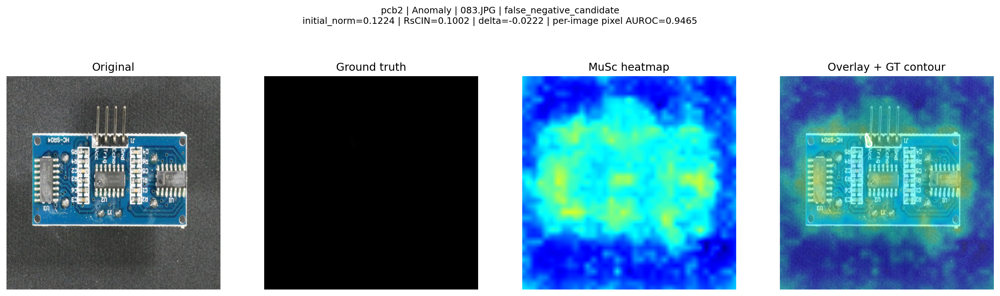

false_negative_candidate Anomaly 063.JPG RsCIN=0.1002


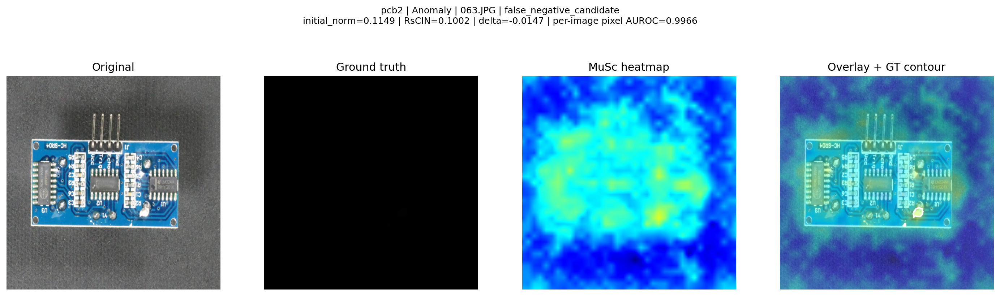

false_positive_candidate Normal 0024.JPG RsCIN=0.3703


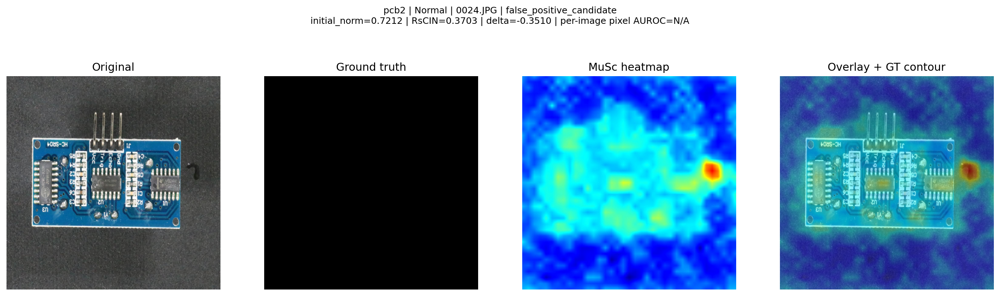

false_positive_candidate Normal 0011.JPG RsCIN=0.3437


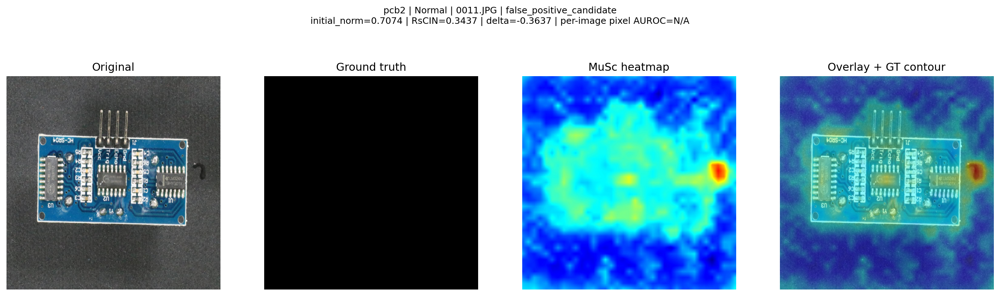

best_localization Anomaly 020.JPG RsCIN=0.6331


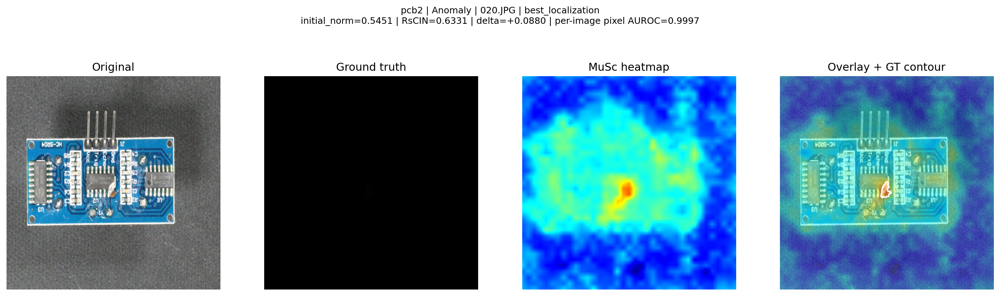

worst_localization Anomaly 047.JPG RsCIN=0.5661


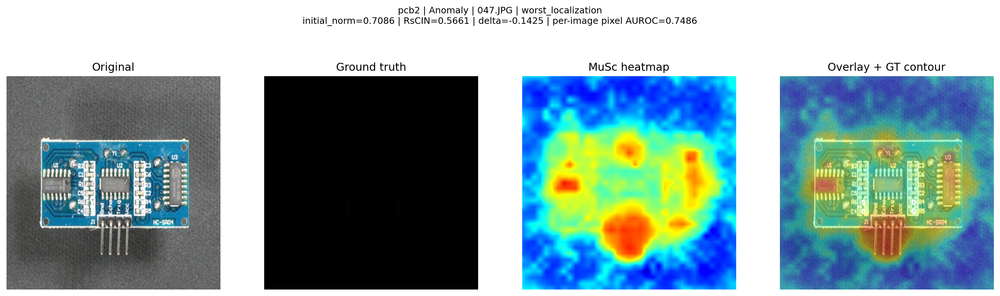


===== pcb3 =====
false_negative_candidate Anomaly 079.JPG RsCIN=0.1690


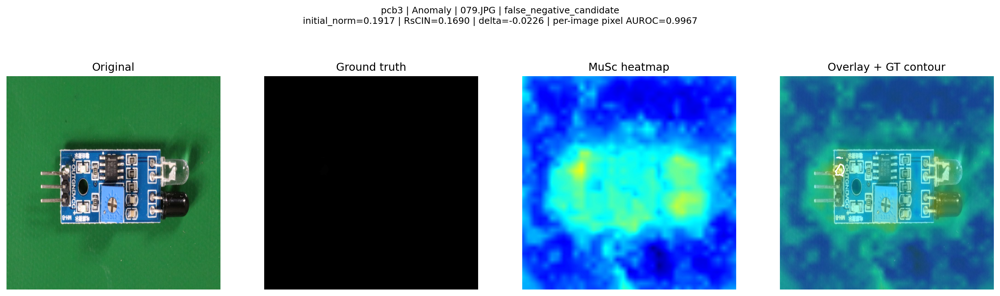

false_negative_candidate Anomaly 042.JPG RsCIN=0.1693


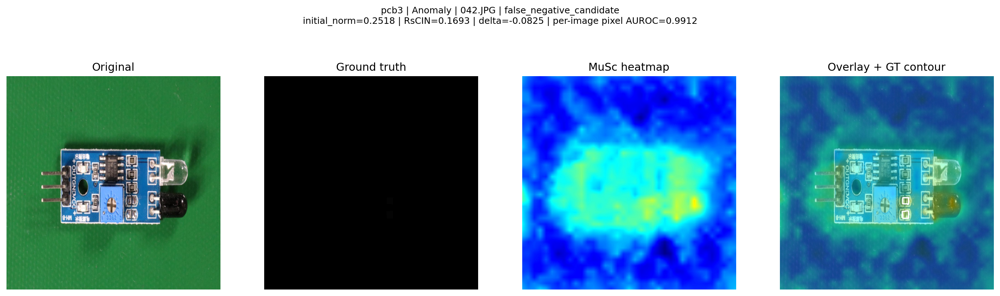

false_positive_candidate Normal 0027.JPG RsCIN=0.3423


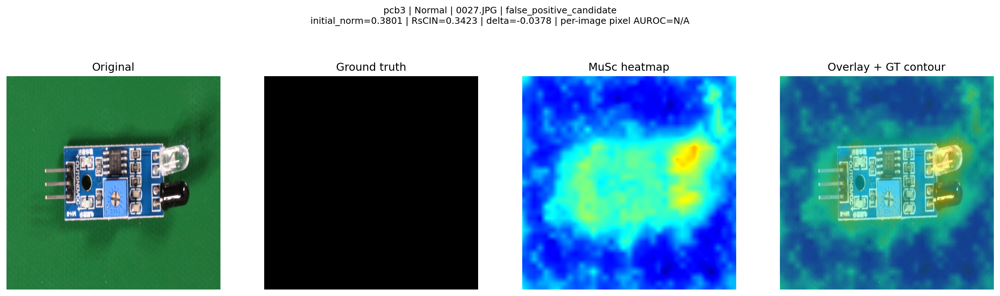

false_positive_candidate Normal 0977.JPG RsCIN=0.2996


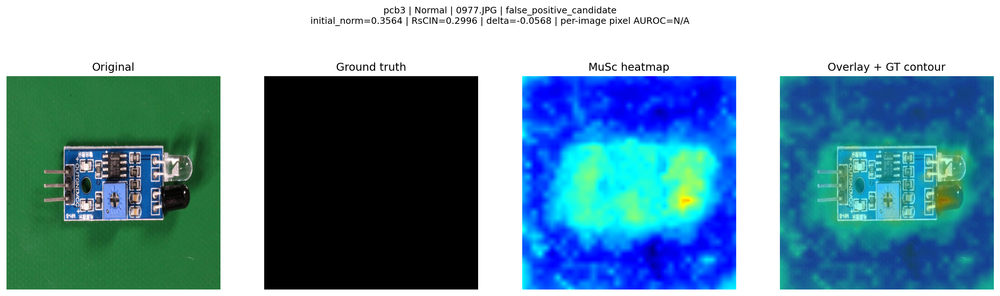

best_localization Anomaly 005.JPG RsCIN=0.4171


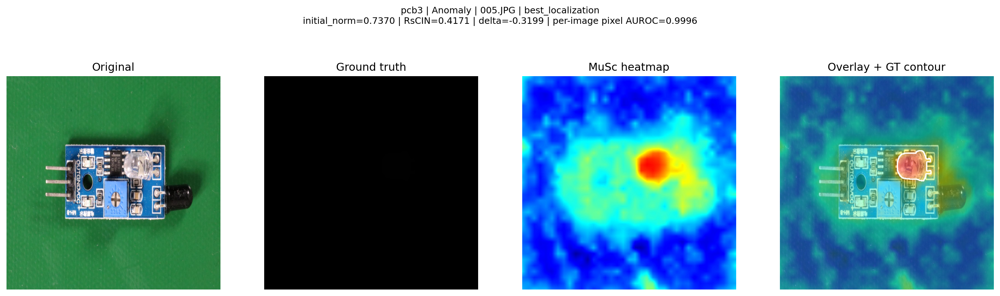

worst_localization Anomaly 043.JPG RsCIN=0.3850


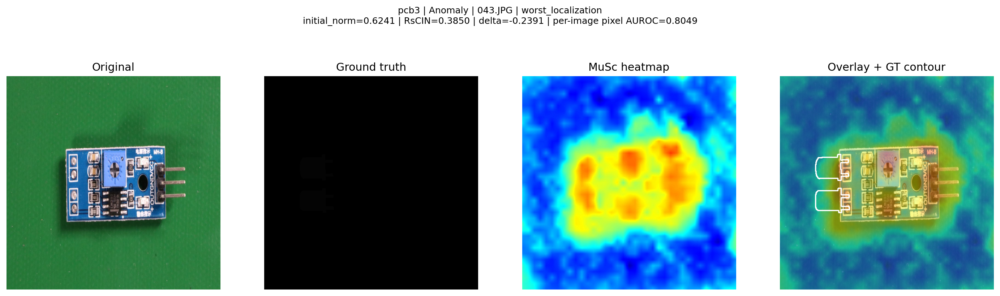


===== pcb4 =====
false_negative_candidate Anomaly 046.JPG RsCIN=0.2480


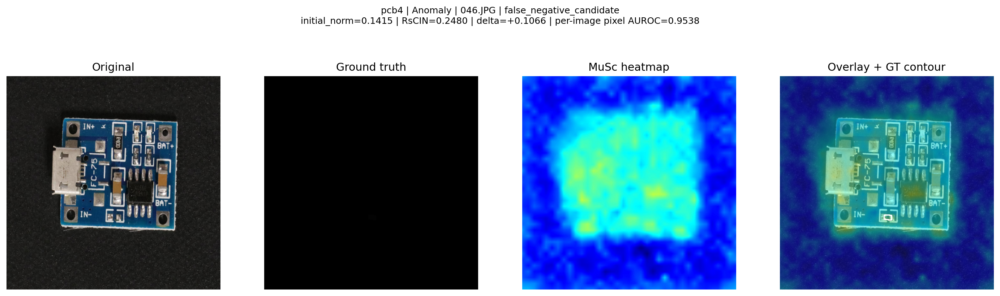

false_negative_candidate Anomaly 047.JPG RsCIN=0.2562


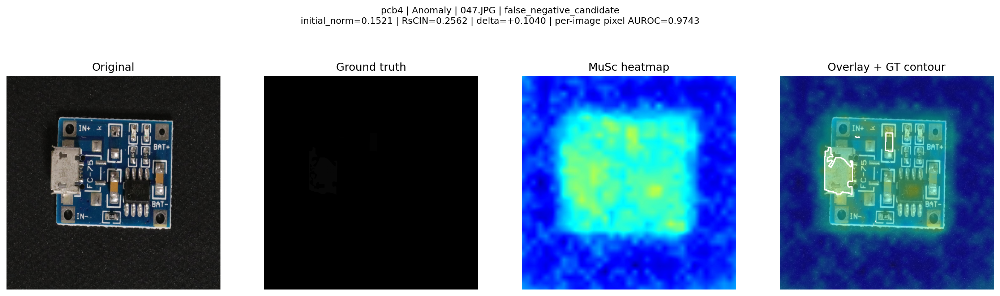

false_positive_candidate Normal 0320.JPG RsCIN=0.3729


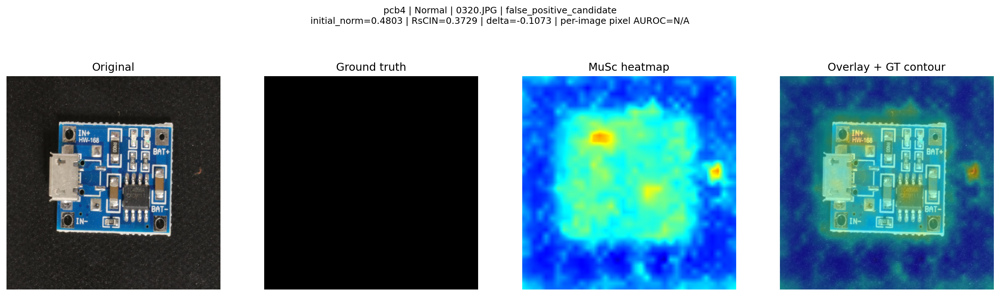

false_positive_candidate Normal 0294.JPG RsCIN=0.3659


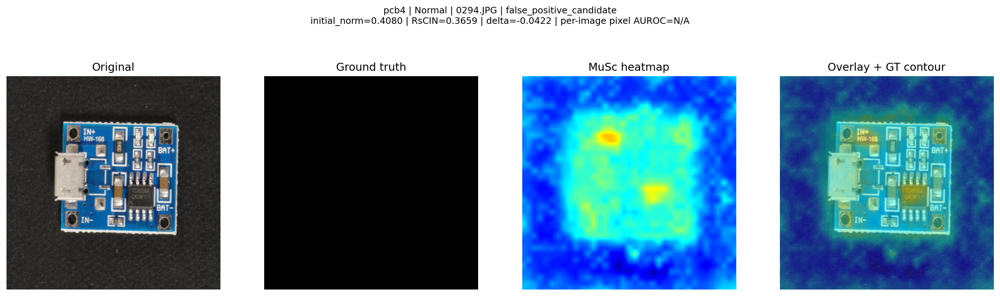

best_localization Anomaly 032.JPG RsCIN=0.4827


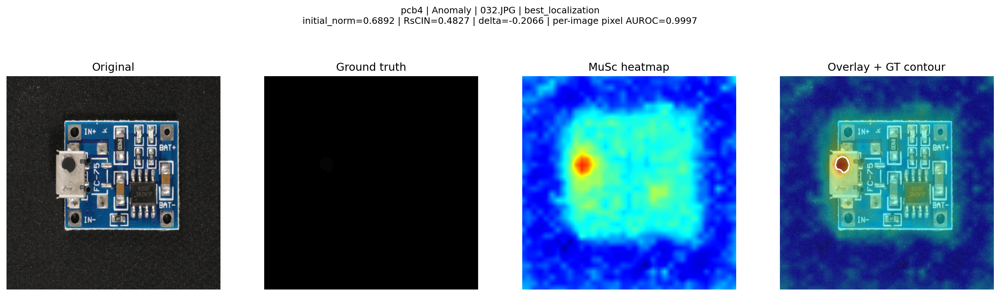

worst_localization Anomaly 061.JPG RsCIN=0.3052


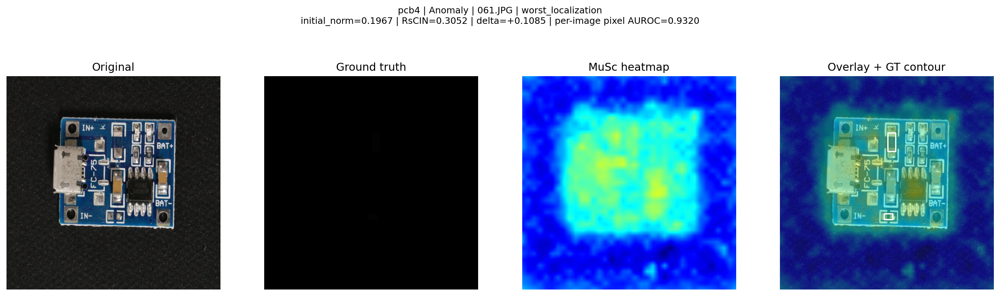


===== fryum =====
false_negative_candidate Anomaly 095.JPG RsCIN=0.0691


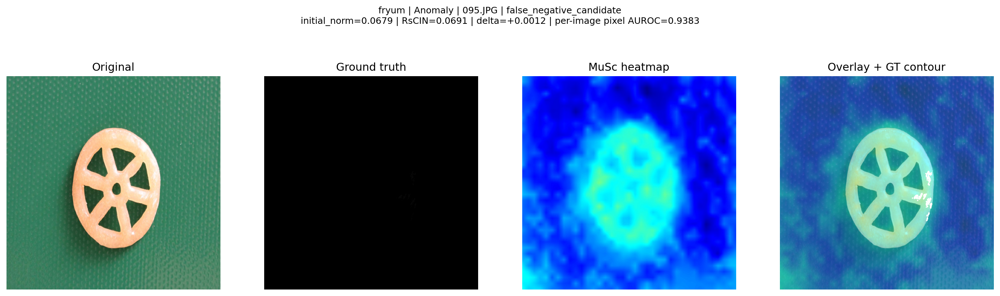

false_negative_candidate Anomaly 094.JPG RsCIN=0.0722


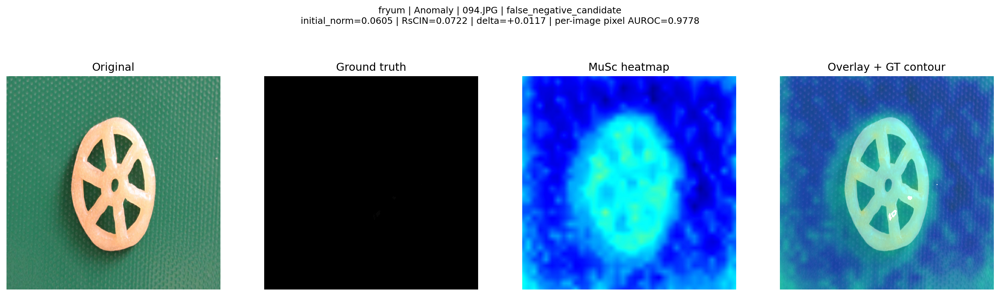

false_positive_candidate Normal 239.JPG RsCIN=0.1193


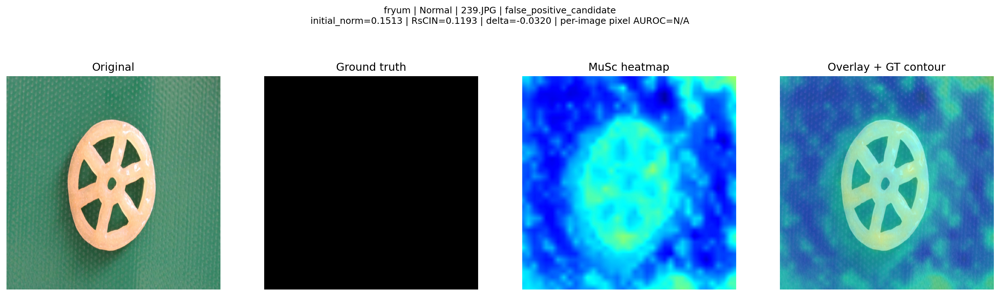

false_positive_candidate Normal 384.JPG RsCIN=0.1148


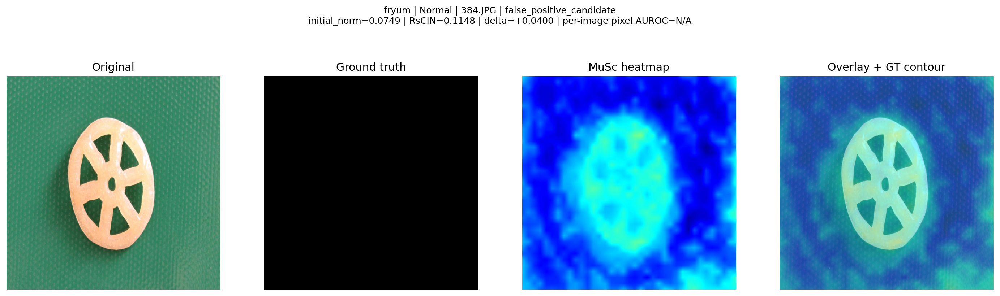

best_localization Anomaly 024.JPG RsCIN=0.1696


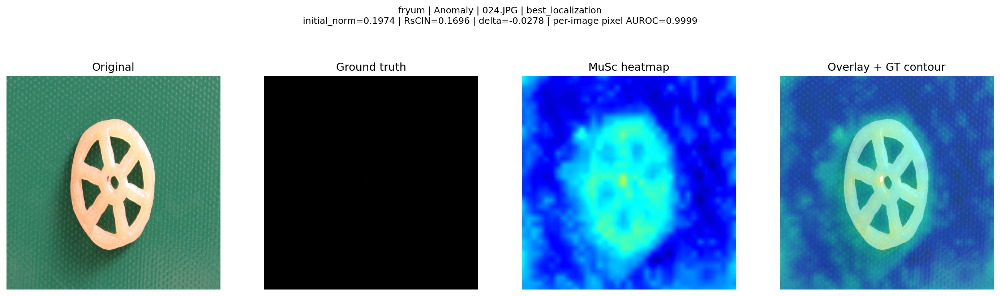

worst_localization Anomaly 010.JPG RsCIN=0.1430


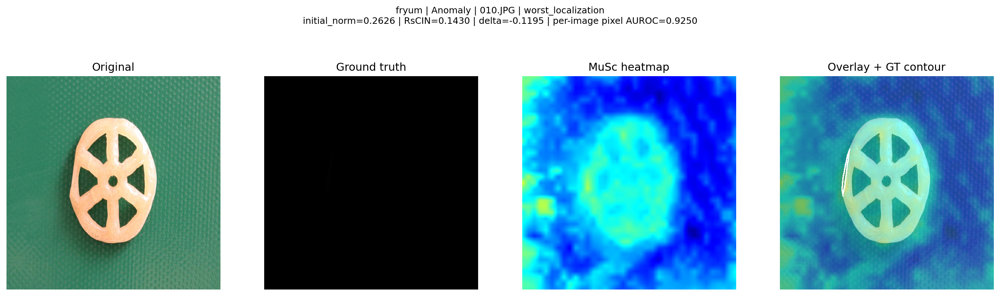

In [ ]:
from IPython.display import display

for category in QUAL_CATEGORIES:
    print(f"\n===== {category} =====")
    rows = asset_index[asset_index["category"] == category]
    for _, row in rows.iterrows():
        print(
            row["selection_reason"],
            row["anomaly_type"],
            Path(row["image_path"]).name,
            f"RsCIN={row['rscin_score']:.4f}",
        )
        display(Image.open(row["panel_path"]))

In [ ]:
import zipfile

successful_attempts = {
    category: successful_qual_attempt(category)
    for category in QUAL_CATEGORIES
}
assert all(path is not None for path in successful_attempts.values())
assert len(asset_index) == 24
assert asset_index["panel_path"].map(lambda path: Path(path).is_file()).all()

metrics_records = [
    json.loads((attempt / "metrics.json").read_text(encoding="utf-8"))
    for attempt in successful_attempts.values()
]
max_metric_delta = max(
    record["max_absolute_delta_from_e02"] for record in metrics_records
)
assert max_metric_delta <= 0.05

summary_lines = [
    "# E02Q VisA Qualitative Summary",
    "",
    f"- Run ID: `{RUN_ID}`",
    f"- Source E02 Run ID: `{SOURCE_E02_RUN_ID}`",
    f"- Categories: {', '.join(QUAL_CATEGORIES)}",
    f"- Selected cases: {len(asset_index)}",
    f"- Maximum absolute metric delta from E02: {max_metric_delta:.12g} percentage points",
    "",
    "## Selection Counts",
    "",
]
for reason, count in asset_index["selection_reason"].value_counts().sort_index().items():
    summary_lines.append(f"- {reason}: {int(count)}")

(RUN_ROOT / "E02Q_SUMMARY.md").write_text(
    "\n".join(summary_lines) + "\n",
    encoding="utf-8",
)

done = {
    "run_id": RUN_ID,
    "source_e02_run_id": SOURCE_E02_RUN_ID,
    "completed_at_utc": datetime.now(timezone.utc).isoformat(),
    "categories": QUAL_CATEGORIES,
    "selected_case_count": int(len(asset_index)),
    "max_absolute_metric_delta_from_e02": float(max_metric_delta),
    "status": "completed",
}
(RUN_ROOT / "E02Q_DONE.json").write_text(
    json.dumps(done, indent=2) + "\n", encoding="utf-8"
)

if (
    ACTIVE_Q_RUN_FILE.is_file()
    and ACTIVE_Q_RUN_FILE.read_text(encoding="utf-8").strip() == RUN_ID
):
    ACTIVE_Q_RUN_FILE.unlink()

zip_path = EXPORT_ROOT / f"{RUN_ID}.zip"
with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as archive:
    for path in RUN_ROOT.rglob("*"):
        if not path.is_file():
            continue
        relative = path.relative_to(RUN_ROOT)
        if "output" in relative.parts:
            continue
        archive.write(path, arcname=str(relative))

with zipfile.ZipFile(zip_path) as archive:
    bad_member = archive.testzip()
    assert bad_member is None, f"ZIP lỗi tại: {bad_member}"
    names = archive.namelist()
    assert "E02Q_DONE.json" in names
    assert "selected-qualitative-cases.csv" in names
    assert "selected-assets-index.csv" in names
    assert not any("/output/" in f"/{name}" for name in names)

print("E02Q hoàn tất.")
print("ZIP:", zip_path)
print("Dung lượng ZIP:", zip_path.stat().st_size / 2**20, "MiB")

E02Q hoàn tất.
ZIP: /content/drive/MyDrive/CS2203_MuSc/exports/20261014_050040_E02Q_visa_qualitative.zip
Dung lượng ZIP: 54.441396713256836 MiB
